<a href="https://colab.research.google.com/github/bhavininigam-eng/Bank-transactions-analyzer/blob/main/Bank_transactions_Analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Bank Transactions Analyzer")
print("Libraries imported successfully!")

Bank Transactions Analyzer
Libraries imported successfully!


In [2]:
data = {
    'Transaction_ID': [101, 102, 103, 104, 105,
                       106, 107, 108, 109, 110,
                       111, 112, 113, 114, 115],

    'Date': [
        '2026-01-02', '2026-01-05', '2026-01-08',
        '2026-01-10', '2026-01-15', '2026-01-18',
        '2026-01-20', '2026-01-23', '2026-02-02',
        '2026-02-05', '2026-02-10', '2026-02-15',
        '2026-02-18', '2026-02-20', '2026-02-25'
    ],

    'Description': [
        'Salary', 'Groceries', 'Shopping',
        'Electricity Bill', 'Freelance Payment',
        'Restaurant', 'Transport', 'Internet Bill',
        'Salary', 'Shopping', 'Groceries',
        'Freelance Payment', 'Movie', 'Electricity Bill',
        'Transport'
    ],

    'Category': [
        'Income', 'Food', 'Shopping',
        'Bills', 'Income', 'Food', 'Travel',
        'Bills', 'Income', 'Shopping', 'Food',
        'Income', 'Entertainment', 'Bills', 'Travel'
    ],

    'Transaction_Type': [
        'Credit', 'Debit', 'Debit', 'Debit', 'Credit',
        'Debit', 'Debit', 'Debit', 'Credit', 'Debit',
        'Debit', 'Credit', 'Debit', 'Debit', 'Debit'
    ],

    'Amount': [
        50000, 2500, 4000, 1800, 8000,
        1200, 500, 700, 50000, 3500,
        2000, 10000, 800, 1800, 600
    ]
}

df = pd.DataFrame(data)

df['Date'] = pd.to_datetime(df['Date'])

print("Dataset created successfully!")

Dataset created successfully!


In [3]:
print("BANK TRANSACTION RECORDS")

display(df)

BANK TRANSACTION RECORDS


,Transaction_ID,Date,Description,Category,Transaction_Type,Amount
0,101,2026-01-02,Salary,Income,Credit,50000
1,102,2026-01-05,Groceries,Food,Debit,2500
2,103,2026-01-08,Shopping,Shopping,Debit,4000
3,104,2026-01-10,Electricity Bill,Bills,Debit,1800
4,105,2026-01-15,Freelance Payment,Income,Credit,8000
5,106,2026-01-18,Restaurant,Food,Debit,1200
6,107,2026-01-20,Transport,Travel,Debit,500
7,108,2026-01-23,Internet Bill,Bills,Debit,700
8,109,2026-02-02,Salary,Income,Credit,50000
9,110,2026-02-05,Shopping,Shopping,Debit,3500


In [4]:
total_income = df[df['Transaction_Type'] == 'Credit']['Amount'].sum()

total_expenses = df[df['Transaction_Type'] == 'Debit']['Amount'].sum()

balance = total_income - total_expenses

print("BANK ACCOUNT SUMMARY")
print("----------------------------")

print("Total Income: ₹", total_income)
print("Total Expenses: ₹", total_expenses)
print("Remaining Balance: ₹", balance)

BANK ACCOUNT SUMMARY
----------------------------
Total Income: ₹ 118000
Total Expenses: ₹ 19400
Remaining Balance: ₹ 98600


In [5]:
highest_transaction = df.loc[df['Amount'].idxmax()]

lowest_transaction = df.loc[df['Amount'].idxmin()]

print("HIGHEST TRANSACTION")
print(highest_transaction)

print("\nLOWEST TRANSACTION")
print(lowest_transaction)

HIGHEST TRANSACTION
Transaction_ID                      101
Date                2026-01-02 00:00:00
Description                      Salary
Category                         Income
Transaction_Type                 Credit
Amount                            50000
Name: 0, dtype: object

LOWEST TRANSACTION
Transaction_ID                      107
Date                2026-01-20 00:00:00
Description                   Transport
Category                         Travel
Transaction_Type                  Debit
Amount                              500
Name: 6, dtype: object


In [6]:
expenses = df[df['Transaction_Type'] == 'Debit']

category_expenses = expenses.groupby('Category')['Amount'].sum()

print("CATEGORY-WISE EXPENSES")
display(category_expenses)

CATEGORY-WISE EXPENSES


,Amount
Category,
Bills,4300
Entertainment,800
Food,5700
Shopping,7500
Travel,1100


In [7]:
df['Month'] = df['Date'].dt.strftime('%B')

monthly_summary = df.groupby(
    ['Month', 'Transaction_Type']
)['Amount'].sum().unstack(fill_value=0)

print("MONTHLY FINANCIAL SUMMARY")

display(monthly_summary)

MONTHLY FINANCIAL SUMMARY


Transaction_Type,Credit,Debit
Month,,
February,60000,8700
January,58000,10700


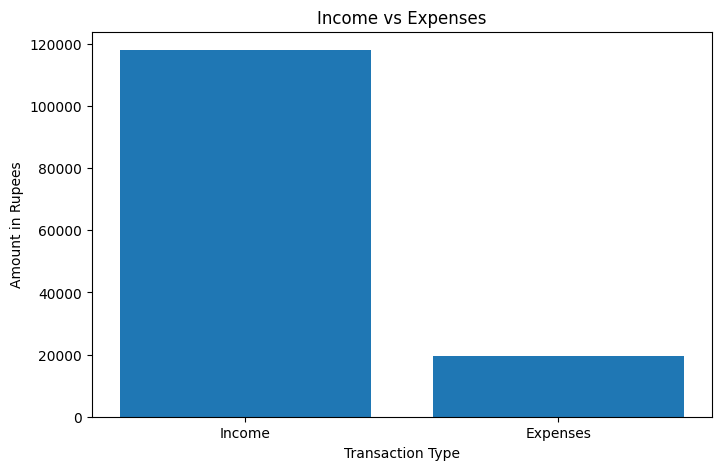

In [8]:
labels = ['Income', 'Expenses']
values = [total_income, total_expenses]

plt.figure(figsize=(8, 5))

plt.bar(labels, values)

plt.title('Income vs Expenses')
plt.xlabel('Transaction Type')
plt.ylabel('Amount in Rupees')

plt.show()

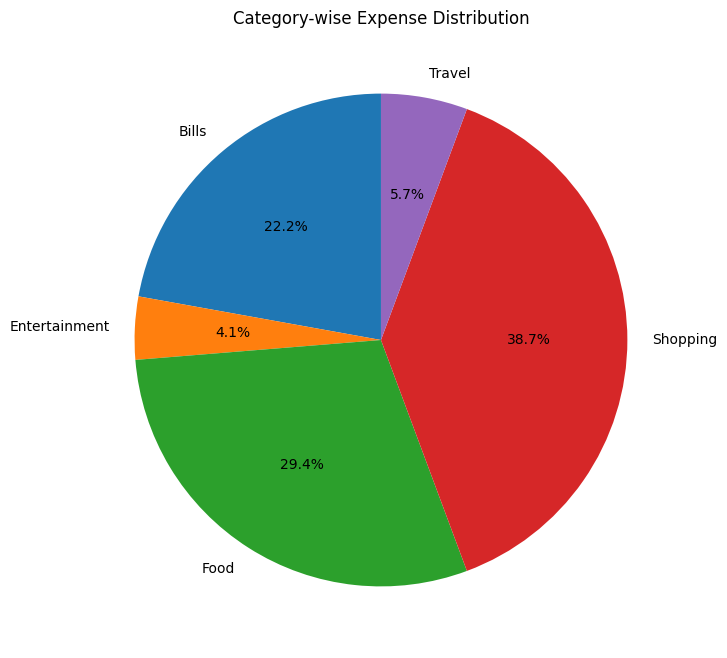

In [9]:
plt.figure(figsize=(8, 8))

category_expenses.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Category-wise Expense Distribution')
plt.ylabel('')

plt.show()

In [10]:
df.to_csv('Bank_Transactions.csv', index=False)

print("Bank transaction data saved successfully!")

Bank transaction data saved successfully!


In [11]:
from google.colab import files

files.download('Bank_Transactions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
search_category = input("Enter category to search: ")

result = df[df['Category'].str.lower() ==
            search_category.lower()]

if not result.empty:
    print("Transactions found:")
    display(result)
else:
    print("No transactions found!")

Enter category to search: food
Transactions found:


,Transaction_ID,Date,Description,Category,Transaction_Type,Amount,Month
1,102,2026-01-05,Groceries,Food,Debit,2500,January
5,106,2026-01-18,Restaurant,Food,Debit,1200,January
10,111,2026-02-10,Groceries,Food,Debit,2000,February


In [13]:
print("===================================")
print("     BANK TRANSACTIONS REPORT")
print("===================================")

print("Total Transactions:", len(df))

print("Total Income: ₹", total_income)

print("Total Expenses: ₹", total_expenses)

print("Available Balance: ₹", balance)

print("Highest Transaction: ₹", df['Amount'].max())

print("Lowest Transaction: ₹", df['Amount'].min())

print("===================================")
print("       ANALYSIS COMPLETED")
print("===================================")

     BANK TRANSACTIONS REPORT
Total Transactions: 15
Total Income: ₹ 118000
Total Expenses: ₹ 19400
Available Balance: ₹ 98600
Highest Transaction: ₹ 50000
Lowest Transaction: ₹ 500
       ANALYSIS COMPLETED
